Ambil data PM25 Per jam tahun 2023

Mulai mengunduh data kualitas udara Kota Cirebon...

[SUKSES] Data berhasil diunduh!
Total baris data: 8760 jam rekaman.
--------------------------------------------------
Preview 5 Data Pertama:
                     pm2_5
waktu                     
2023-01-01 00:00:00   20.8
2023-01-01 01:00:00   19.3
2023-01-01 02:00:00   17.5
2023-01-01 03:00:00   15.6
2023-01-01 04:00:00   14.1
--------------------------------------------------


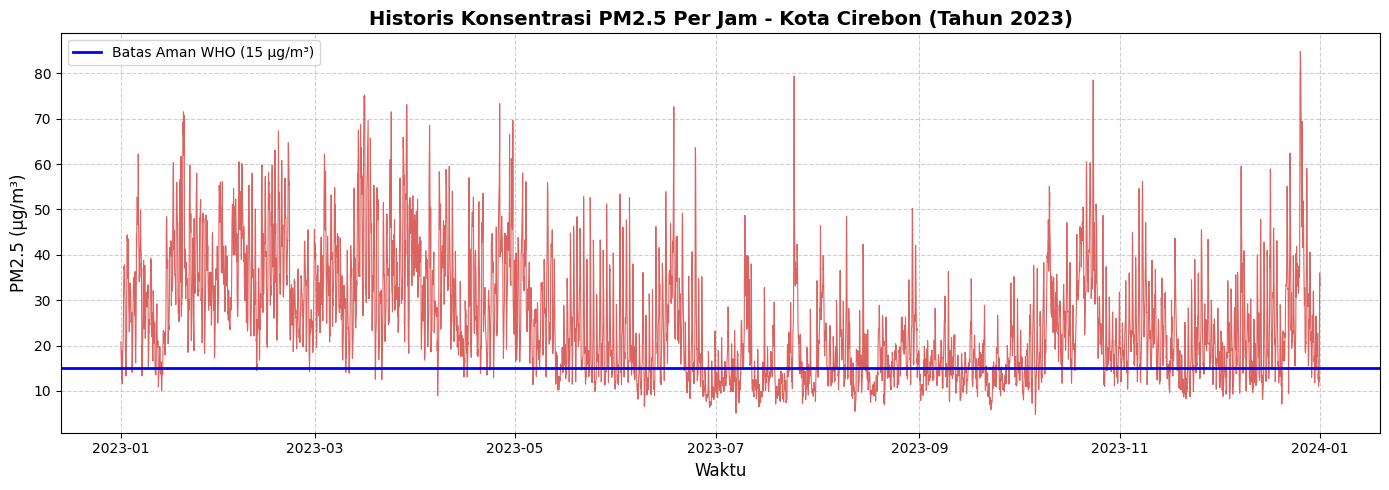


[INFO] Dataset telah disimpan di Google Colab Anda dengan nama: 'dataset_pm25_cirebon_2023_hourly.csv'


In [ ]:
# ==============================================================================
# SCRIPT EKSTRAKSI DATA KUALITAS UDARA (PM2.5) KOTA CIREBON - DIPERBAIKI
# ==============================================================================

import requests
import pandas as pd
import matplotlib.pyplot as plt

def get_cirebon_air_quality():
    print("Mulai mengunduh data kualitas udara Kota Cirebon...")

    # 1. Menentukan Endpoint dan Parameter (Diperbarui ke Tahun 2023)
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        "latitude": -6.7126,
        "longitude": 108.5694,
        "start_date": "2023-01-01", # Menggunakan data 2023 karena API global aktif mulai Agustus 2022
        "end_date": "2023-12-31",
        "hourly": "pm2_5",
        "timezone": "Asia/Jakarta"
    }

    # 2. Menarik Data dari API
    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()

        # 3. Memasukkan JSON ke dalam struktur Pandas DataFrame
        df = pd.DataFrame({
            "waktu": data["hourly"]["time"],
            "pm2_5": data["hourly"]["pm2_5"]
        })

        # 4. PREPROCESSING TIME-SERIES DASAR
        # Mengubah kolom waktu menjadi tipe datetime
        df['waktu'] = pd.to_datetime(df['waktu'])

        # Mengisi nilai yang kosong (missing values) dengan metode interpolasi linier
        df['pm2_5'] = df['pm2_5'].interpolate(method='linear')

        # Menjadikan kolom waktu sebagai Index
        df.set_index('waktu', inplace=True)

        print("\n[SUKSES] Data berhasil diunduh!")
        print(f"Total baris data: {len(df)} jam rekaman.")
        print("-" * 50)
        print("Preview 5 Data Pertama:")
        print(df.head())
        print("-" * 50)

        # 5. Visualisasi Data Historis
        plt.figure(figsize=(14, 5))
        plt.plot(df.index, df['pm2_5'], color='#d9534f', linewidth=0.8, alpha=0.9)
        plt.title('Historis Konsentrasi PM2.5 Per Jam - Kota Cirebon (Tahun 2023)', fontsize=14, fontweight='bold')
        plt.xlabel('Waktu', fontsize=12)
        plt.ylabel('PM2.5 (µg/m³)', fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.6)

        # Menambahkan garis batas aman rata-rata harian menurut WHO (15 µg/m³)
        plt.axhline(y=15, color='b', linestyle='-', linewidth=2, label='Batas Aman WHO (15 µg/m³)')
        plt.legend()
        plt.tight_layout()
        plt.show()

        # 6. Menyimpan ke dalam CSV
        filename = "dataset_pm25_cirebon_2023_hourly.csv"
        df.to_csv(filename)
        print(f"\n[INFO] Dataset telah disimpan di Google Colab Anda dengan nama: '{filename}'")

        return df
    else:
        print(f"Gagal mengambil data. Status code: {response.status_code}")
        return None

# Menjalankan fungsi
df_cirebon = get_cirebon_air_quality()

Ambil data cuaca per jam tahun 2023

In [ ]:
# ==============================================================================
# SCRIPT EKSTRAKSI DATA CUACA HISTORIS KOTA CIREBON (TAHUN 2023)
# Sumber API: Open-Meteo Historical Weather API (Gratis, Tanpa API Key)
# ==============================================================================

import requests
import pandas as pd

def get_cirebon_weather():
    print("Mulai mengunduh data cuaca historis Kota Cirebon...")

    # 1. Menentukan Endpoint dan Parameter (Koordinat dan Waktu SAMA PERSIS dengan PM2.5)
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": -6.7126,
        "longitude": 108.5694,
        "start_date": "2023-01-01",
        "end_date": "2023-12-31",
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m",
        "timezone": "Asia/Jakarta"
    }

    # 2. Menarik Data dari API
    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()

        # 3. Memasukkan JSON ke dalam Pandas DataFrame
        df_cuaca = pd.DataFrame({
            "waktu": data["hourly"]["time"],
            "suhu_C": data["hourly"]["temperature_2m"],
            "kelembapan_%": data["hourly"]["relative_humidity_2m"],
            "curah_hujan_mm": data["hourly"]["precipitation"],
            "angin_kmh": data["hourly"]["wind_speed_10m"]
        })

        # 4. PREPROCESSING DASAR
        # Mengubah kolom waktu menjadi tipe datetime dan menjadikannya Index
        df_cuaca['waktu'] = pd.to_datetime(df_cuaca['waktu'])
        df_cuaca.set_index('waktu', inplace=True)

        # Mengisi nilai kosong (jika ada) dengan metode forward fill (mengisi dengan nilai jam sebelumnya)
        df_cuaca.fillna(method='ffill', inplace=True)

        print("\n[SUKSES] Data cuaca berhasil diunduh!")
        print(f"Total baris data: {len(df_cuaca)} jam rekaman.")
        print("-" * 50)
        print("Preview 5 Data Pertama:")
        print(df_cuaca.head())
        print("-" * 50)

        # 5. Menyimpan ke dalam CSV
        filename = "dataset_cuaca_cirebon_2023_hourly.csv"
        df_cuaca.to_csv(filename)
        print(f"\n[INFO] Dataset cuaca telah disimpan dengan nama: '{filename}'")

        return df_cuaca
    else:
        print(f"Gagal mengambil data cuaca. Status code: {response.status_code}")
        return None

# Menjalankan fungsi
df_cuaca = get_cirebon_weather()

Mulai mengunduh data cuaca historis Kota Cirebon...

[SUKSES] Data cuaca berhasil diunduh!
Total baris data: 8760 jam rekaman.
--------------------------------------------------
Preview 5 Data Pertama:
                     suhu_C  kelembapan_%  curah_hujan_mm  angin_kmh
waktu                                                               
2023-01-01 00:00:00    23.9            92             0.0       16.3
2023-01-01 01:00:00    23.9            92             0.0       16.9
2023-01-01 02:00:00    23.6            92             0.0       18.4
2023-01-01 03:00:00    23.7            91             0.0       20.0
2023-01-01 04:00:00    23.5            91             0.1       20.7
--------------------------------------------------

[INFO] Dataset cuaca telah disimpan dengan nama: 'dataset_cuaca_cirebon_2023_hourly.csv'


/tmp/ipykernel_27828/1871458474.py:44: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_cuaca.fillna(method='ffill', inplace=True)


Merging Data

In [ ]:
# ==============================================================================
# SCRIPT PENGGABUNGAN DATA (MERGING) UNTUK DATASET MULTIVARIAT
# ==============================================================================

import pandas as pd

def merge_datasets():
    print("Mulai menggabungkan dataset PM2.5 dan Cuaca...")

    try:
        # 1. Membaca kedua file CSV yang sudah Anda unduh sebelumnya
        # Kita langsung mendefinisikan kolom 'waktu' sebagai tipe datetime dan menjadikannya Index
        df_pm25 = pd.read_csv("dataset_pm25_cirebon_2023_hourly.csv", parse_dates=['waktu'], index_col='waktu')
        df_cuaca = pd.read_csv("dataset_cuaca_cirebon_2023_hourly.csv", parse_dates=['waktu'], index_col='waktu')

        # 2. Proses Penggabungan (Merging)
        # Menggunakan metode 'inner join' berdasarkan Index (waktu)
        # Ini menjamin PM2.5 dan cuaca disatukan pada tanggal dan jam yang sama persis
        df_master = pd.merge(df_pm25, df_cuaca, left_index=True, right_index=True, how='inner')

        # 3. Validasi Akhir (Pembersihan Data Lanjutan)
        # Berjaga-jaga jika ada baris yang kosong akibat proses penggabungan
        df_master.fillna(method='ffill', inplace=True)

        print("\n[SUKSES] Dataset Master Multivariat berhasil dibuat!")
        print(f"Total baris: {df_master.shape[0]} | Total kolom: {df_master.shape[1]}")
        print("-" * 60)

        # 4. Menampilkan Struktur Data Master
        print("--- INFO DATASET MASTER ---")
        df_master.info()

        print("\n--- PREVIEW 5 DATA PERTAMA ---")
        print(df_master.head())
        print("-" * 60)

        # 5. Menyimpan ke CSV Final
        filename = "dataset_master_multivariat_cirebon_2023.csv"
        df_master.to_csv(filename)
        print(f"\n[INFO] Dataset Master telah disimpan dan siap digunakan: '{filename}'")

        return df_master

    except FileNotFoundError as e:
        print(f"\n[ERROR] File tidak ditemukan. Pastikan Anda sudah menjalankan script PM2.5 dan Cuaca sebelumnya. Detail: {e}")
        return None

# Menjalankan fungsi
df_master_final = merge_datasets()

Mulai menggabungkan dataset PM2.5 dan Cuaca...

[SUKSES] Dataset Master Multivariat berhasil dibuat!
Total baris: 8760 | Total kolom: 5
------------------------------------------------------------
--- INFO DATASET MASTER ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8760 entries, 2023-01-01 00:00:00 to 2023-12-31 23:00:00
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pm2_5           8760 non-null   float64
 1   suhu_C          8760 non-null   float64
 2   kelembapan_%    8760 non-null   int64  
 3   curah_hujan_mm  8760 non-null   float64
 4   angin_kmh       8760 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 410.6 KB

--- PREVIEW 5 DATA PERTAMA ---
                     pm2_5  suhu_C  kelembapan_%  curah_hujan_mm  angin_kmh
waktu                                                                      
2023-01-01 00:00:00   20.8    23.9            92             0.0       16.3
2023-0

/tmp/ipykernel_27828/3811039139.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_master.fillna(method='ffill', inplace=True)


Preprocessing Data

In [ ]:
# ==============================================================================
# SCRIPT DATA PREPROCESSING (TRAIN-TEST SPLIT, SCALING, & SLIDING WINDOW)
# ==============================================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import pickle

def preprocess_time_series():
    print("Mulai proses Data Preprocessing untuk LSTM...\n")

    try:
        # 1. LOAD DATA MASTER
        df = pd.read_csv("dataset_master_multivariat_cirebon_2023.csv", index_col='waktu', parse_dates=True)

        # 2. TRAIN-TEST SPLIT (Secara Kronologis)
        # Kita menggunakan 80% data untuk melatih model, dan 20% sisanya untuk ujian.
        # TIDAK BOLEH di-shuffle secara acak (random) karena ini data deret waktu.
        train_size = int(len(df) * 0.80)
        train_df = df.iloc[:train_size]
        test_df = df.iloc[train_size:]

        print(f"✅ Tahap 1: Pembagian Data Berhasil")
        print(f"   -> Data Latih (Train): {len(train_df)} baris")
        print(f"   -> Data Uji (Test)   : {len(test_df)} baris\n")

        # 3. NORMALISASI (MIN-MAX SCALING)
        # Mengubah semua rentang angka menjadi 0 hingga 1.
        # WAJIB: Scaler hanya di-fit (diajarkan) pada Data Latih untuk mencegah 'Data Leakage'.
        scaler_features = MinMaxScaler()
        train_scaled = scaler_features.fit_transform(train_df)
        test_scaled = scaler_features.transform(test_df)

        # Kita buat satu scaler khusus hanya untuk PM2.5 (berada di kolom ke-0)
        # Ini akan sangat berguna nanti untuk mengembalikan nilai prediksi ke skala asli (µg/m³)
        scaler_target = MinMaxScaler()
        scaler_target.fit(train_df[['pm2_5']])

        print(f"✅ Tahap 2: Normalisasi Berhasil (Skala diubah menjadi 0-1)\n")

        # 4. SLIDING WINDOW (MEMBUAT SEKUEN / JENDELA WAKTU)
        # Fungsi ini mengubah tabel 2D menjadi matriks 3D yang disukai LSTM
        def create_sequences(data, window_size, target_col_index=0):
            X, y = [], []
            # Geser jendela satu per satu dari awal sampai akhir
            for i in range(len(data) - window_size):
                # X (Fitur): Ambil 24 jam ke belakang dari SEMUA kolom (cuaca & pm2.5)
                X.append(data[i:(i + window_size)])
                # y (Target): Ambil 1 jam ke depan HANYA dari kolom PM2.5
                y.append(data[i + window_size, target_col_index])
            return np.array(X), np.array(y)

        # Menetapkan ukuran jendela: 24 jam
        window_size = 24

        X_train, y_train = create_sequences(train_scaled, window_size)
        X_test, y_test = create_sequences(test_scaled, window_size)

        print(f"✅ Tahap 3: Sliding Window (Pembuatan Sekuen) Berhasil")
        print(f"   -> Ukuran Jendela Waktu (Window Size) = {window_size} Jam")
        print("-" * 60)

        # 5. VALIDASI BENTUK MATRIKS (TENSOR)
        print("--- DIMENSI MATRIKS UNTUK INPUT LSTM ---")
        print(f"X_train Shape : {X_train.shape} --> (Total Sampel Latih, {window_size} Jam, {X_train.shape[2]} Fitur)")
        print(f"y_train Shape : {y_train.shape} --> (Total Target Latih)")
        print(f"X_test Shape  : {X_test.shape} --> (Total Sampel Uji, {window_size} Jam, {X_test.shape[2]} Fitur)")
        print(f"y_test Shape  : {y_test.shape} --> (Total Target Uji)")
        print("-" * 60)

        # Simpan array numpy agar langsung bisa digunakan di tahap training
        np.save('X_train.npy', X_train)
        np.save('y_train.npy', y_train)
        np.save('X_test.npy', X_test)
        np.save('y_test.npy', y_test)

        # Simpan scaler target untuk tahap evaluasi nanti
        with open('scaler_target.pkl', 'wb') as f:
            pickle.dump(scaler_target, f)

        print("\n[INFO] Data X_train, y_train, X_test, dan y_test telah disimpan dengan format .npy!")
        print("[INFO] Scaler untuk target PM2.5 telah disimpan sebagai 'scaler_target.pkl'.")

        return X_train, y_train, X_test, y_test

    except Exception as e:
        print(f"\n[ERROR] Terjadi kesalahan saat memproses data. Detail: {e}")
        return None, None, None, None

# Eksekusi fungsi
X_train, y_train, X_test, y_test = preprocess_time_series()

Mulai proses Data Preprocessing untuk LSTM...

✅ Tahap 1: Pembagian Data Berhasil
   -> Data Latih (Train): 7008 baris
   -> Data Uji (Test)   : 1752 baris

✅ Tahap 2: Normalisasi Berhasil (Skala diubah menjadi 0-1)

✅ Tahap 3: Sliding Window (Pembuatan Sekuen) Berhasil
   -> Ukuran Jendela Waktu (Window Size) = 24 Jam
------------------------------------------------------------
--- DIMENSI MATRIKS UNTUK INPUT LSTM ---
X_train Shape : (6984, 24, 5) --> (Total Sampel Latih, 24 Jam, 5 Fitur)
y_train Shape : (6984,) --> (Total Target Latih)
X_test Shape  : (1728, 24, 5) --> (Total Sampel Uji, 24 Jam, 5 Fitur)
y_test Shape  : (1728,) --> (Total Target Uji)
------------------------------------------------------------

[INFO] Data X_train, y_train, X_test, dan y_test telah disimpan dengan format .npy!
[INFO] Scaler untuk target PM2.5 telah disimpan sebagai 'scaler_target.pkl'.
